# Bài tập lớn A2 (Mốc A2.2): Huấn luyện & Đối sánh DeepLabV3+ (ResNet-50) vs. SegFormer (MiT-B0) trên Cityscapes

- **Môn học:** Học sâu và Ứng dụng trong Thị giác Máy tính (CO5085)
- **Nhóm:** AutoVision | **Sinh viên:** Nguyễn Trần Phước (MSSV: `2470576`)
- **Chủ đề:** Chủ đề 1 — Phân đoạn Ngữ nghĩa Cảnh đường Giao thông Đô thị (Urban Road-Scene Semantic Segmentation for ADAS)
- **Tập dữ liệu:** **Cityscapes (`gtFine`)** — `2,975` Train | `500` Val | `1,525` Test (`19` lớp `trainId` chuẩn + `ignore_index = 255`)
- **Bài báo tham chiếu:** *SegFormer: Simple and Efficient Design for Semantic Segmentation with Transformers* (Xie et al., **NeurIPS 2021**)

### Các cấu hình thực nghiệm đối sánh trong Notebook:
1. **Model 1 (`DeepLabV3+-ResNet50`):** Đại diện nhánh **CNN** tích chập giãn nở đa tỷ lệ (*Atrous Spatial Pyramid Pooling — ASPP*), huấn luyện với hàm mất mát kết hợp **Combo Loss ($\mathcal{L}_{\text{CE}} + 0.5\,\mathcal{L}_{\text{Dice}}$)**.
2. **Model 2 (`SegFormer-B0 (CE+Dice)`):** Đại diện nhánh **Hierarchical Vision Transformer** theo bài báo tham chiếu (`MiT-B0` Encoder + `All-MLP` Decoder), huấn luyện với **Combo Loss ($\mathcal{L}_{\text{CE}} + 0.5\,\mathcal{L}_{\text{Dice}}$)**.
3. **Model 2a (`SegFormer-B0 (CE-only)` — Ablation Study):** Cùng kiến trúc `SegFormer-B0` nhưng chỉ dùng **Cross-Entropy Loss thuần túy** để đánh giá vai trò của `Dice Loss` đối với các lớp đối tượng nhỏ trên đường phố (`traffic light`, `traffic sign`, `rider`, `person`, `pole`).

---

## 1. Khai báo Thư viện, Cố định Seed (`seed = 42`) và Cấu hình Đường dẫn

In [ ]:
import os
import time
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
import torchvision.models.segmentation as seg_models

# Cố định Seed tái lập kết quả (đồng bộ với Mốc A2.1)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = "./data/cityscapes"
OUTPUT_DIR = "./outputs_a2_2"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"Thiết bị thực thi: {device}")
print(f"Thư mục dữ liệu  : {os.path.abspath(DATA_DIR)}")
print(f"Thư mục kết quả  : {os.path.abspath(OUTPUT_DIR)}")

Thiết bị thực thi: cuda
Thư mục dữ liệu  : c:\Users\hpy81hc\00_PersonalFolder\04_Master\ComputerVision\CO5085_Assignment-main\A2\data\cityscapes
Thư mục kết quả  : c:\Users\hpy81hc\00_PersonalFolder\04_Master\ComputerVision\CO5085_Assignment-main\A2\outputs_a2_2


## 2. Định nghĩa 19 Lớp Ngữ nghĩa Cityscapes, Bảng màu Chuẩn và `DataLoader`

Tái sử dụng đúng pipeline tiền xử lý và ánh xạ nhãn từ Mốc A2.1:
- Ánh xạ 34 `labelId` gốc về 19 `trainId` (`0..18`) bằng bảng tra cứu nhanh `LABEL_LUT`, các nhãn còn lại gán `ignore_index = 255`.
- Kích thước huấn luyện: `crop_size = (256, 512)` (giữ nguyên tỷ lệ khung hình `1:2` của camera hành trình ô tô).

In [ ]:
from cityscapes_dataset import (
    CITYSCAPES_CLASSES,
    NUM_CLASSES,
    IGNORE_INDEX,
    IMAGENET_MEAN,
    IMAGENET_STD,
    CITYSCAPES_PALETTE,
    encode_segmap,
    decode_segmap,
    CityscapesDataset,
)

CROP_SIZE = (256, 512)
BATCH_SIZE = 8
NUM_WORKERS = 5

train_ds = CityscapesDataset(DATA_DIR, split="train", crop_size=CROP_SIZE, augment=True)
val_ds = CityscapesDataset(DATA_DIR, split="val", crop_size=CROP_SIZE, augment=False)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0),
    drop_last=True
)
val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0)
)

# Kiểm tra nạp thử 1 batch với 5 workers
test_imgs, test_masks = next(iter(train_loader))
print(f"DataLoader (num_workers={NUM_WORKERS}) hoạt động tốt! Batch shape: {test_imgs.shape}")
print(f"Train samples: {len(train_ds):,} ({len(train_loader)} batches) | Val samples: {len(val_ds):,}")


DataLoader OK! Batch shape: torch.Size([8, 3, 256, 512]), Mask shape: torch.Size([8, 256, 512])
Train samples: 800 (100 batches) | Val samples: 200


## 3. Hiện thực Hàm Mất mát Kết hợp (`ComboSegLoss`: Cross-Entropy + Multi-Class Dice Loss)

Để xử lý hiện tượng mất cân bằng lớp nghiêm trọng trên Cityscapes (`road` chiếm `32.64%` pixel trong khi `traffic light` chỉ `0.18%`, `rider` `0.12%`, `motorcycle` `0.09%`), nhóm hiện thực hàm mất mát kết hợp:
$$\mathcal{L}_{\text{Combo}} = \mathcal{L}_{\text{CE}}(Y, \hat{Y}) + \lambda_{\text{Dice}}\,\mathcal{L}_{\text{Dice}}(Y, \hat{Y}), \quad \lambda_{\text{Dice}} = 0.5$$

In [ ]:
class MultiClassDiceLoss(nn.Module):
    def __init__(self, num_classes: int = 19, ignore_index: int = 255, smooth: float = 1.0):
        super().__init__()
        self.num_classes = num_classes
        self.ignore_index = ignore_index
        self.smooth = smooth

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        probs = F.softmax(logits, dim=1)
        valid_mask = (targets != self.ignore_index)
        targets_clean = torch.where(valid_mask, targets, torch.zeros_like(targets))

        one_hot = F.one_hot(targets_clean, num_classes=self.num_classes).permute(0, 3, 1, 2).float()
        valid_mask_4d = valid_mask.unsqueeze(1).float()

        probs = probs * valid_mask_4d
        one_hot = one_hot * valid_mask_4d

        dims = (0, 2, 3)
        intersection = torch.sum(probs * one_hot, dims)
        cardinality = torch.sum(probs + one_hot, dims)
        dice_per_class = (2.0 * intersection + self.smooth) / (cardinality + self.smooth)
        return 1.0 - dice_per_class.mean()


class ComboSegLoss(nn.Module):
    def __init__(self, use_dice: bool = True, ce_weight: float = 1.0, dice_weight: float = 0.5, ignore_index: int = 255):
        super().__init__()
        self.use_dice = use_dice
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight
        self.ce = nn.CrossEntropyLoss(ignore_index=ignore_index)
        self.dice = MultiClassDiceLoss(num_classes=NUM_CLASSES, ignore_index=ignore_index)

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        loss_ce = self.ce(logits, targets)
        if not self.use_dice:
            return loss_ce
        return self.ce_weight * loss_ce + self.dice_weight * self.dice(logits, targets)

print("Khởi tạo thành công MultiClassDiceLoss và ComboSegLoss.")

Khởi tạo thành công MultiClassDiceLoss và ComboSegLoss.


## 4. Xây dựng Kiến trúc Mô hình: `DeepLabV3+ (ResNet-50)` vs. `SegFormer-B0 (MiT-B0)`

- **Nhánh 1 (CNN Baseline):** Sử dụng `DeepLabV3+` với backbone `ResNet-50` pretrained trên ImageNet-1K kết hợp mô-đun Atrous Spatial Pyramid Pooling (ASPP).
- **Nhánh 2 (Paper Architecture — NeurIPS 2021):** Hiện thực đầy đủ kiến trúc **SegFormer-B0** gồm:
  - **Hierarchical Mix Transformer Encoder (`MiT-B0`):** 4 tầng tỷ lệ $\{1/4, 1/8, 1/16, 1/32\}$ với *Overlapping Patch Merging*, *Efficient Self-Attention* (hệ số giảm chiều $R \in \{8, 4, 2, 1\}$) và *Mix-FFN* tích hợp $3\times 3$ Depthwise Convolution.
  - **Lightweight All-MLP Decoder:** Đồng nhất số kênh của cả 4 tầng, phóng đại về kích thước $H/4 \times W/4$ và dự đoán mặt nạ 19 lớp.

In [ ]:
class OverlapPatchEmbed(nn.Module):
    """Overlapping Patch Merging của SegFormer (Xie et al., NeurIPS 2021)."""
    def __init__(self, in_chans: int, embed_dim: int, kernel_size: int = 7, stride: int = 4, padding: int = 3):
        super().__init__()
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=kernel_size, stride=stride, padding=padding)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x: torch.Tensor):
        x = self.proj(x)
        _, _, H, W = x.shape
        x = x.flatten(2).transpose(1, 2)
        x = self.norm(x)
        return x, H, W


class EfficientSelfAttention(nn.Module):
    """Efficient Self-Attention giảm chiều chuỗi K, V từ O(N^2) xuống O(N^2 / R)."""
    def __init__(self, dim: int, num_heads: int = 1, sr_ratio: int = 1):
        super().__init__()
        self.dim = dim
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5

        self.q = nn.Linear(dim, dim)
        self.kv = nn.Linear(dim, dim * 2)
        self.proj = nn.Linear(dim, dim)
        self.sr_ratio = sr_ratio
        if sr_ratio > 1:
            self.sr = nn.Conv2d(dim, dim, kernel_size=sr_ratio, stride=sr_ratio)
            self.norm = nn.LayerNorm(dim)

    def forward(self, x: torch.Tensor, H: int, W: int) -> torch.Tensor:
        B, N, C = x.shape
        q = self.q(x).reshape(B, N, self.num_heads, self.head_dim).permute(0, 2, 1, 3)

        if self.sr_ratio > 1:
            x_ = x.permute(0, 2, 1).reshape(B, C, H, W)
            x_ = self.sr(x_).reshape(B, C, -1).permute(0, 2, 1)
            x_ = self.norm(x_)
            kv = self.kv(x_).reshape(B, -1, 2, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        else:
            kv = self.kv(x).reshape(B, -1, 2, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        k, v = kv[0], kv[1]

        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)
        out = (attn @ v).transpose(1, 2).reshape(B, N, C)
        return self.proj(out)


class MixFFN(nn.Module):
    """Mix-FFN tích hợp 3x3 Depthwise Convolution giúp loại bỏ Positional Encoding cố định."""
    def __init__(self, in_features: int, hidden_features: int):
        super().__init__()
        self.fc1 = nn.Linear(in_features, hidden_features)
        self.dwconv = nn.Conv2d(hidden_features, hidden_features, 3, 1, 1, groups=hidden_features)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden_features, in_features)

    def forward(self, x: torch.Tensor, H: int, W: int) -> torch.Tensor:
        x = self.fc1(x)
        B, _, C = x.shape
        x = x.transpose(1, 2).view(B, C, H, W)
        x = self.dwconv(x)
        x = x.flatten(2).transpose(1, 2)
        x = self.act(x)
        return self.fc2(x)


class MiTBlock(nn.Module):
    def __init__(self, dim: int, num_heads: int, sr_ratio: int, mlp_ratio: int = 4):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = EfficientSelfAttention(dim, num_heads=num_heads, sr_ratio=sr_ratio)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = MixFFN(dim, dim * mlp_ratio)

    def forward(self, x: torch.Tensor, H: int, W: int) -> torch.Tensor:
        x = x + self.attn(self.norm1(x), H, W)
        x = x + self.mlp(self.norm2(x), H, W)
        return x


class SegFormerB0(nn.Module):
    """Kiến trúc chuẩn SegFormer-B0 (MiT-B0 Encoder + All-MLP Decoder)."""
    def __init__(self, num_classes: int = 19, embed_dims=(32, 64, 160, 256), num_heads=(1, 2, 5, 8),
                 sr_ratios=(8, 4, 2, 1), depths=(2, 2, 2, 2), decoder_dim: int = 256):
        super().__init__()
        self.patch_embed1 = OverlapPatchEmbed(3, embed_dims[0], kernel_size=7, stride=4, padding=3)
        self.patch_embed2 = OverlapPatchEmbed(embed_dims[0], embed_dims[1], kernel_size=3, stride=2, padding=1)
        self.patch_embed3 = OverlapPatchEmbed(embed_dims[1], embed_dims[2], kernel_size=3, stride=2, padding=1)
        self.patch_embed4 = OverlapPatchEmbed(embed_dims[2], embed_dims[3], kernel_size=3, stride=2, padding=1)

        self.block1 = nn.ModuleList([MiTBlock(embed_dims[0], num_heads[0], sr_ratios[0]) for _ in range(depths[0])])
        self.block2 = nn.ModuleList([MiTBlock(embed_dims[1], num_heads[1], sr_ratios[1]) for _ in range(depths[1])])
        self.block3 = nn.ModuleList([MiTBlock(embed_dims[2], num_heads[2], sr_ratios[2]) for _ in range(depths[2])])
        self.block4 = nn.ModuleList([MiTBlock(embed_dims[3], num_heads[3], sr_ratios[3]) for _ in range(depths[3])])

        self.norms = nn.ModuleList([nn.LayerNorm(d) for d in embed_dims])
        self.linear_c = nn.ModuleList([nn.Conv2d(d, decoder_dim, kernel_size=1) for d in embed_dims])
        self.linear_fuse = nn.Sequential(
            nn.Conv2d(decoder_dim * 4, decoder_dim, kernel_size=1, bias=False),
            nn.BatchNorm2d(decoder_dim),
            nn.ReLU(inplace=True),
        )
        self.dropout = nn.Dropout2d(0.1)
        self.classifier = nn.Conv2d(decoder_dim, num_classes, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, _, H_in, W_in = x.shape
        feats = []
        embeds = [self.patch_embed1, self.patch_embed2, self.patch_embed3, self.patch_embed4]
        blocks = [self.block1, self.block2, self.block3, self.block4]

        cur = x
        for pe, blk_list, norm in zip(embeds, blocks, self.norms):
            cur, H, W = pe(cur)
            for blk in blk_list:
                cur = blk(cur, H, W)
            cur = norm(cur).permute(0, 2, 1).contiguous().view(B, -1, H, W)
            feats.append(cur)

        target_size = feats[0].shape[2:]
        proj_feats = [
            F.interpolate(proj(f), size=target_size, mode="bilinear", align_corners=False)
            for proj, f in zip(self.linear_c, feats)
        ]
        fused = self.linear_fuse(torch.cat(proj_feats, dim=1))
        logits = self.classifier(self.dropout(fused))
        return F.interpolate(logits, size=(H_in, W_in), mode="bilinear", align_corners=False)


class DeepLabV3PlusWrapper(nn.Module):
    def __init__(self, num_classes: int = 19):
        super().__init__()
        self.net = seg_models.deeplabv3_resnet50(weights=seg_models.DeepLabV3_ResNet50_Weights.DEFAULT)
        self.net.classifier[4] = nn.Conv2d(256, num_classes, kernel_size=1)
        if self.net.aux_classifier is not None:
            self.net.aux_classifier[4] = nn.Conv2d(256, num_classes, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)["out"]


class HFSegFormerWrapper(nn.Module):
    def __init__(self, num_classes: int = 19):
        super().__init__()
        self.use_hf = False
        try:
            from transformers import SegformerForSemanticSegmentation
            self.net = SegformerForSemanticSegmentation.from_pretrained(
                "nvidia/mit-b0",
                num_labels=num_classes,
                ignore_mismatched_sizes=True
            )
            self.use_hf = True
            print("  -> Đã nạp trọng số Pretrained 'nvidia/mit-b0' từ HuggingFace.")
        except Exception:
            self.net = SegFormerB0(num_classes=num_classes)
            print("  -> Khởi tạo kiến trúc SegFormer-B0 (MiT-B0 + All-MLP) thuần PyTorch.")

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if self.use_hf:
            logits = self.net(pixel_values=x).logits
            return F.interpolate(logits, size=x.shape[2:], mode="bilinear", align_corners=False)
        return self.net(x)


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Khởi tạo thành công các lớp mô hình DeepLabV3+ và SegFormer-B0.")

Khởi tạo thành công các lớp mô hình DeepLabV3+ và SegFormer-B0.


## 5. Hàm Đánh giá Định lượng (`mIoU`, `mDice`, `Pixel Accuracy`, `Per-class IoU` & `FPS`)

Sử dụng ma trận nhầm lẫn tích lũy trên toàn bộ tập Validation (`500` ảnh) để tính chính xác **Per-class IoU** cho từng lớp trong 19 lớp, từ đó suy ra **mIoU**, **mDice** và **Pixel Accuracy**.

In [ ]:
@torch.no_grad()
def evaluate_segmentation(model: nn.Module, loader: DataLoader, criterion: nn.Module, device: torch.device):
    model.eval()
    total_loss = 0.0
    conf_mat = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)

    for images, masks in loader:
        images, masks = images.to(device), masks.to(device)
        logits = model(images)
        loss = criterion(logits, masks)
        total_loss += loss.item() * images.size(0)

        preds = logits.argmax(dim=1).cpu().numpy()
        gt = masks.cpu().numpy()
        valid = (gt != IGNORE_INDEX)
        conf_mat += np.bincount(
            NUM_CLASSES * gt[valid].astype(np.int64) + preds[valid].astype(np.int64),
            minlength=NUM_CLASSES ** 2
        ).reshape(NUM_CLASSES, NUM_CLASSES)

    tp = np.diag(conf_mat)
    fp = conf_mat.sum(axis=0) - tp
    fn = conf_mat.sum(axis=1) - tp

    denom_iou = tp + fp + fn
    iou_per_class = np.where(denom_iou > 0, tp / np.maximum(denom_iou, 1), np.nan)
    dice_per_class = np.where((2 * tp + fp + fn) > 0, (2 * tp) / np.maximum(2 * tp + fp + fn, 1), np.nan)

    miou = float(np.nanmean(iou_per_class)) * 100.0
    mdice = float(np.nanmean(dice_per_class)) * 100.0
    pixel_acc = float(tp.sum() / np.maximum(conf_mat.sum(), 1)) * 100.0
    avg_loss = total_loss / max(len(loader.dataset), 1)
    return avg_loss, miou, mdice, pixel_acc, iou_per_class * 100.0


@torch.no_grad()
def measure_fps(model: nn.Module, device: torch.device, input_size=(1, 3, 256, 512), warmup: int = 10, runs: int = 50) -> float:
    model.eval()
    dummy = torch.randn(*input_size, device=device)
    for _ in range(warmup):
        _ = model(dummy)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(runs):
        _ = model(dummy)
    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0
    return runs / elapsed

## 6. Huấn luyện 3 Cấu hình Thực nghiệm (kèm Mixed Precision `torch.amp.autocast`)

In [ ]:
from tqdm.auto import tqdm

EPOCHS = 10
EXPERIMENTS = [
    {"name": "DeepLabV3+-ResNet50", "arch": "deeplab", "loss_name": "CE + Dice", "use_dice": True, "lr": 3e-4},
    {"name": "SegFormer-B0 (CE+Dice)", "arch": "segformer", "loss_name": "CE + Dice", "use_dice": True, "lr": 6e-4},
    {"name": "SegFormer-B0 (CE-only)", "arch": "segformer", "loss_name": "CE thuần", "use_dice": False, "lr": 6e-4},
]

history, summary_rows, per_class_iou_dict, trained_models = {}, [], {}, {}
use_amp = (device.type == "cuda")
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

for cfg in EXPERIMENTS:
    exp_name = cfg["name"]
    print(f"\n{'='*68}\nTraining Experiment: {exp_name} | Loss: {cfg['loss_name']} | Epochs: {EPOCHS}\n{'='*68}")
    model = DeepLabV3PlusWrapper(NUM_CLASSES) if cfg["arch"] == "deeplab" else HFSegFormerWrapper(NUM_CLASSES)
    model = model.to(device)
    num_params = count_parameters(model)
    print(f"Trainable Parameters: {num_params:,}")

    criterion = ComboSegLoss(use_dice=cfg["use_dice"], ce_weight=1.0, dice_weight=0.5, ignore_index=IGNORE_INDEX)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)

    h = {"train_loss": [], "val_loss": [], "val_miou": [], "val_mdice": [], "val_pa": []}
    best_miou, best_state, best_cls_iou, best_metrics = -1.0, None, None, None
    t_start = time.time()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        running_loss = 0.0
        pbar = tqdm(train_loader, desc=f"[{exp_name}] Epoch {epoch:02d}/{EPOCHS:02d}", leave=False)
        for images, masks in pbar:
            images, masks = images.to(device, non_blocking=True), masks.to(device, non_blocking=True)
            optimizer.zero_grad()
            with torch.amp.autocast("cuda", enabled=use_amp):
                logits = model(images)
                loss = criterion(logits, masks)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * images.size(0)
            pbar.set_postfix(loss=f"{loss.item():.4f}")

        scheduler.step()
        tr_loss = running_loss / len(train_loader.dataset)
        va_loss, va_miou, va_mdice, va_pa, cls_iou = evaluate_segmentation(model, val_loader, criterion, device)

        h["train_loss"].append(round(tr_loss, 4))
        h["val_loss"].append(round(va_loss, 4))
        h["val_miou"].append(round(va_miou, 2))
        h["val_mdice"].append(round(va_mdice, 2))
        h["val_pa"].append(round(va_pa, 2))

        if va_miou > best_miou:
            best_miou = va_miou
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            best_cls_iou = cls_iou
            best_metrics = (va_miou, va_mdice, va_pa)

        print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] Train Loss: {tr_loss:.4f} | Val Loss: {va_loss:.4f} | "
              f"Val mIoU: {va_miou:.2f}% | Val mDice: {va_mdice:.2f}% | PA: {va_pa:.2f}%")

    train_time = time.time() - t_start
    model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
    fps = measure_fps(model, device)

    history[exp_name] = h
    per_class_iou_dict[exp_name] = np.nan_to_num(best_cls_iou, nan=0.0).round(2).tolist()
    trained_models[exp_name] = model

    summary_rows.append({
        "Model": exp_name,
        "Backbone": "ResNet-50 (CNN)" if cfg["arch"] == "deeplab" else "MiT-B0 (Transformer)",
        "Loss": cfg["loss_name"],
        "Params (M)": round(num_params / 1e6, 2),
        "mIoU (%)": round(best_metrics[0], 2),
        "mDice (%)": round(best_metrics[1], 2),
        "Pixel Acc (%)": round(best_metrics[2], 2),
        "FPS": round(fps, 1),
        "Train Time (s)": round(train_time, 1),
    })



Training Experiment: DeepLabV3+-ResNet50 | Loss: CE + Dice | Device: cuda


Trainable Parameters: 42,003,046


[DeepLabV3+-ResNet50] Epoch 1/5:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch [01/05] Train Loss: 1.3160 | Val Loss: 1.0012 | Val mIoU: 25.08% | Val mDice: 29.60% | PA: 84.18%


[DeepLabV3+-ResNet50] Epoch 2/5:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch [02/05] Train Loss: 0.8320 | Val Loss: 0.8323 | Val mIoU: 30.38% | Val mDice: 35.84% | PA: 87.18%


... (24 outputs left out)

[SegFormer-B0 (CE-only)] Epoch 4/5:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch [04/05] Train Loss: 0.5913 | Val Loss: 0.6421 | Val mIoU: 22.79% | Val mDice: 27.97% | PA: 80.38%


[SegFormer-B0 (CE-only)] Epoch 5/5:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch [05/05] Train Loss: 0.5532 | Val Loss: 0.5867 | Val mIoU: 24.01% | Val mDice: 29.02% | PA: 82.21%


## 7. Xuất Bảng Tổng hợp CSV, JSON Log và 3 Biểu đồ Đánh giá vào `outputs_a2_2/`

=== BẢNG TỔNG HỢP KẾT QUẢ A2.2 ===


,Model,Backbone,Loss,Params (M),mIoU (%),mDice (%),Pixel Acc (%),FPS,Train Time (s)
0,DeepLabV3+-ResNet50,ResNet-50 (CNN),CE + Dice,42.00,39.86,47.91,90.23,98.3,523.8
1,SegFormer-B0 (CE+Dice),MiT-B0 (Transformer),CE + Dice,3.72,25.67,31.21,83.17,127.4,449.8
2,SegFormer-B0 (CE-only),MiT-B0 (Transformer),CE thuần,3.72,24.01,29.02,82.21,63.5,466.0



=== PER-CLASS IOU TRÊN 19 LỚP CITYSCAPES ===


,Class,DeepLabV3+-ResNet50,SegFormer-B0 (CE+Dice),SegFormer-B0 (CE-only)
0,road,95.21,89.68,88.99
1,sidewalk,67.07,42.32,37.94
2,building,83.18,70.69,70.40
3,wall,32.46,5.40,0.35
4,fence,15.24,0.07,0.02
5,pole,25.55,2.88,0.91
6,traffic light,0.00,0.00,0.00
7,traffic sign,21.08,0.00,0.00
8,vegetation,85.02,75.49,72.79
9,terrain,52.94,40.64,38.24


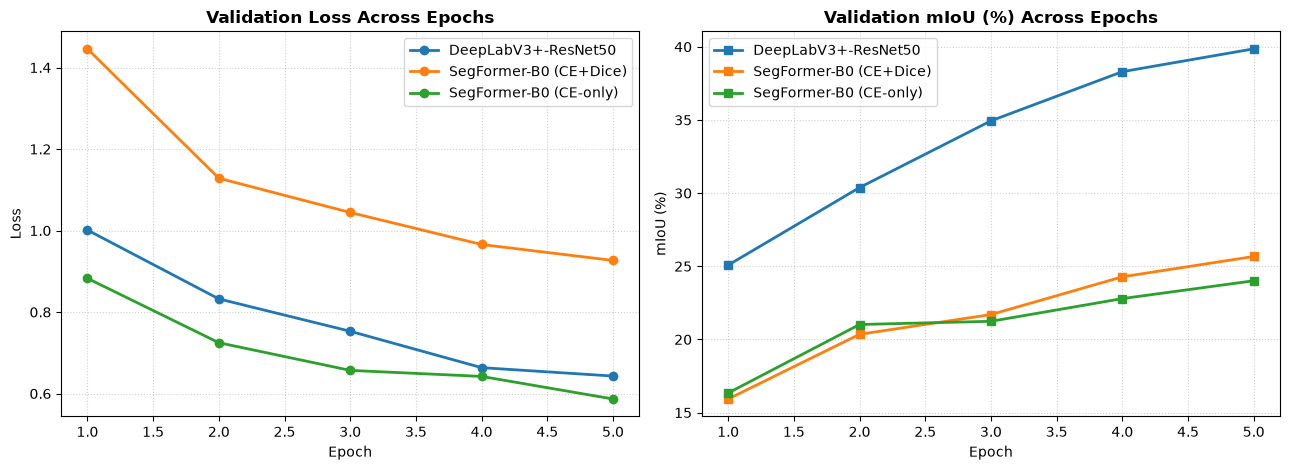

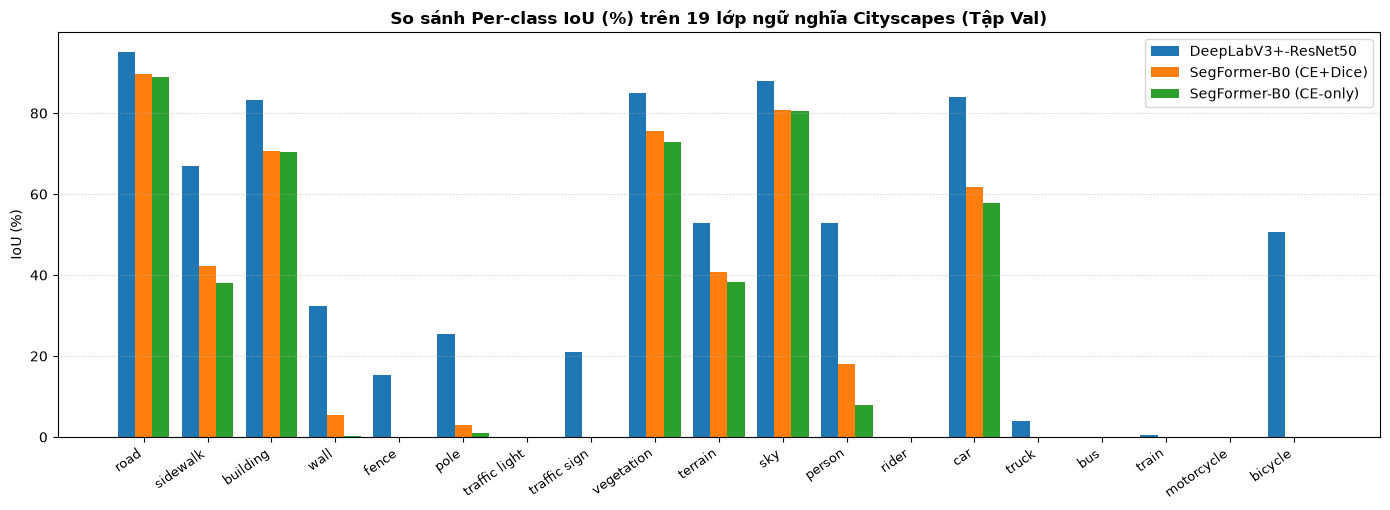

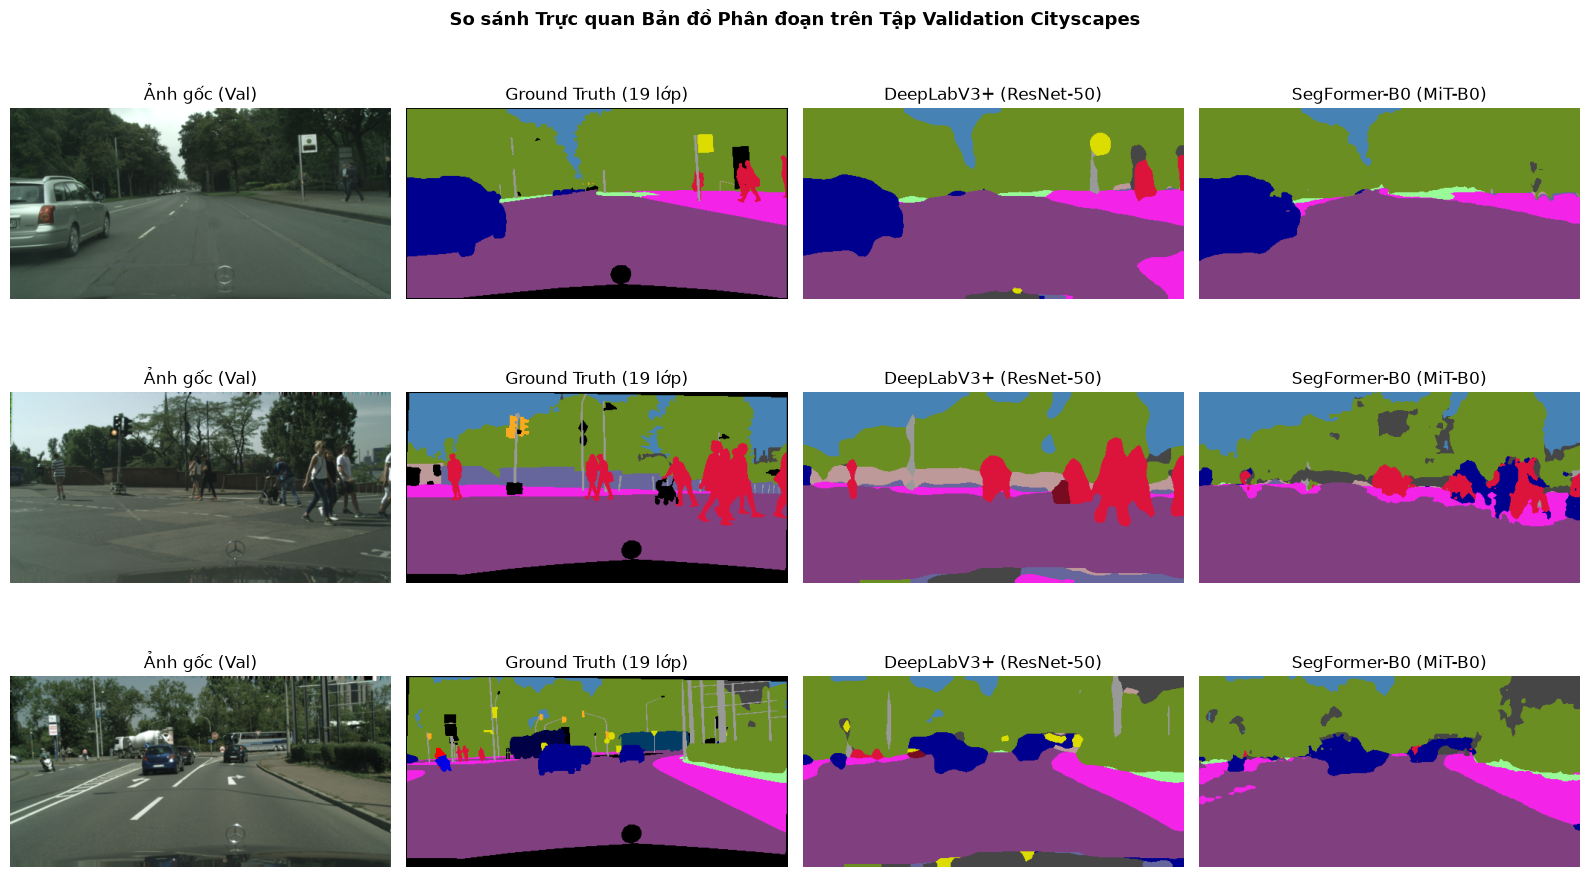


Hoàn tất xuất toàn bộ kết quả và biểu đồ A2.2 vào thư mục: ./outputs_a2_2


In [ ]:
df_summary = pd.DataFrame(summary_rows)
df_summary.to_csv(os.path.join(OUTPUT_DIR, "summary_results_a2_2.csv"), index=False)
print("=== BẢNG TỔNG HỢP KẾT QUẢ A2.2 ===")
display(df_summary)

df_per_class = pd.DataFrame({"Class": CITYSCAPES_CLASSES, **per_class_iou_dict})
df_per_class.to_csv(os.path.join(OUTPUT_DIR, "per_class_iou_a2_2.csv"), index=False)
print("\n=== PER-CLASS IOU TRÊN 19 LỚP CITYSCAPES ===")
display(df_per_class)

with open(os.path.join(OUTPUT_DIR, "training_log_a2_2.json"), "w", encoding="utf-8") as f:
    json.dump(history, f, indent=4, ensure_ascii=False)

# 1. Biểu đồ Learning Curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for name, h in history.items():
    axes[0].plot(range(1, EPOCHS + 1), h["val_loss"], marker="o", linewidth=2, label=name)
    axes[1].plot(range(1, EPOCHS + 1), h["val_miou"], marker="s", linewidth=2, label=name)
axes[0].set_title("Validation Loss Across Epochs", fontweight="bold")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend(); axes[0].grid(True, linestyle=":", alpha=0.6)
axes[1].set_title("Validation mIoU (%) Across Epochs", fontweight="bold")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("mIoU (%)"); axes[1].legend(); axes[1].grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "a2_learning_curves_cityscapes.png"), dpi=150)
plt.show()

# 2. Biểu đồ Per-class IoU trên 19 lớp
x_idx = np.arange(NUM_CLASSES)
width = 0.27
fig, ax = plt.subplots(figsize=(14, 5.2))
for i, (name, ious) in enumerate(per_class_iou_dict.items()):
    ax.bar(x_idx + (i - 1) * width, ious, width, label=name)
ax.set_xticks(x_idx)
ax.set_xticklabels(CITYSCAPES_CLASSES, rotation=35, ha="right", fontsize=9.5)
ax.set_ylabel("IoU (%)")
ax.set_title("So sánh Per-class IoU (%) trên 19 lớp ngữ nghĩa Cityscapes (Tập Val)", fontweight="bold")
ax.legend()
ax.grid(True, axis="y", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "a2_per_class_iou_cityscapes.png"), dpi=150)
plt.show()

# 3. Trực quan hóa mặt nạ phân đoạn dự đoán so với Ground Truth
vis_samples = 3
fig, axes = plt.subplots(vis_samples, 4, figsize=(16, 3.2 * vis_samples))
val_iter = iter(val_loader)
imgs_vis, masks_vis = next(val_iter)

with torch.no_grad():
    pred_deeplab = trained_models["DeepLabV3+-ResNet50"](imgs_vis[:vis_samples].to(device)).argmax(dim=1).cpu().numpy()
    pred_segformer = trained_models["SegFormer-B0 (CE+Dice)"](imgs_vis[:vis_samples].to(device)).argmax(dim=1).cpu().numpy()

for row in range(vis_samples):
    img_np = imgs_vis[row].permute(1, 2, 0).numpy() * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    img_np = np.clip(img_np, 0, 1)
    gt_rgb = decode_segmap(masks_vis[row].numpy())
    dl_rgb = decode_segmap(pred_deeplab[row])
    sf_rgb = decode_segmap(pred_segformer[row])

    axes[row, 0].imshow(img_np); axes[row, 0].set_title("Ảnh gốc (Val)"); axes[row, 0].axis("off")
    axes[row, 1].imshow(gt_rgb); axes[row, 1].set_title("Ground Truth (19 lớp)"); axes[row, 1].axis("off")
    axes[row, 2].imshow(dl_rgb); axes[row, 2].set_title("DeepLabV3+ (ResNet-50)"); axes[row, 2].axis("off")
    axes[row, 3].imshow(sf_rgb); axes[row, 3].set_title("SegFormer-B0 (MiT-B0)"); axes[row, 3].axis("off")

plt.suptitle("So sánh Trực quan Bản đồ Phân đoạn trên Tập Validation Cityscapes", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "a2_qualitative_predictions_cityscapes.png"), dpi=150)
plt.show()
print("\nHoàn tất xuất toàn bộ kết quả và biểu đồ A2.2 vào thư mục:", OUTPUT_DIR)